# `Random forest`

In [1]:
print("This is a Random forest section")

This is a Random forest section


In [2]:
# What is Random Forest ? 

#Random Forest is an ensemble machine learning algorithm that builds many Decision Trees and combines their predictions to produce a stronger and more stable model.

# It can be used for classification and regression . 

# for now, we will focus on random forest classification .



# WHy do wee need random forest ? 
# I already know that single decision tree can have a problem . 

# Training data - very deep tree - Memorizes training data - training accuracy = 100% but poor generalization . 

# Random forest tries to solve this problem by using many different decision trees instead of relying on one tree . 

# All about discuss about below the link . 

https://docs.google.com/document/d/13l7vI1RtdODLPKv-TJYZ1moHhksaHnpp-33L62ibQqs/edit?usp=sharing

# Related this topic notes and interview Q&A

https://docs.google.com/document/d/1Wc8JNV2KzYU2eyD1xofp_grVbo5C6K06AINsN41WI2o/edit?usp=sharing


# Coding

`Import library`


In [1]:
import numpy as np # import numpy for numerical operation
import pandas as pd # import pandas for tabular data

from sklearn.datasets import load_breast_cancer # load dataset from sklearn
from sklearn.model_selection import train_test_split # split the data set into train and test
from sklearn.ensemble import RandomForestClassifier # import random forest classifier . 
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report 
# accuracy_score - calculate accuracy , a single number representing the percentage of correct predicts out of all total predicts.

# confusion matrix - A grid layout that breaks down exactly where the model succeeded and where it made mistakes . Exactly what types of mistakes am i making ?

# classification report - how well am i doing on each individual class using , precision, recall, F1-score

import matplotlib.pyplot as plt

/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/sklearn/utils/_param_validation.py:14: UserWarning: A NumPy version >=2.0.0 and <2.8.0 is required for this version of SciPy (detected version 1.26.4)
  from scipy.sparse import csr_array, issparse
/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/scipy/sparse/_sputils.py:17: FutureWarning: In the future `np.long` will be defined as the corresponding NumPy scalar.
  np.uintc, np.long, np.ulong, np.longlong, np.ulonglong,


AttributeError: module 'numpy' has no attribute 'long'

`Understand the dataset`

In [3]:
cancer_data = load_breast_cancer()
cancer = cancer_data

In [5]:
print(cancer.data.shape,"First Number sample or rows and second number number of features and columns")

(569, 30) First Number sample or rows and second number number of features and columns


`Check the target shape`

In [6]:
cancer.target.shape
# so we have one target values for each of the 569 samples

(569,)

In [7]:
# check the feature names
cancer.feature_names

#These are measurements extracted from breast tumor images.


array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

In [8]:
# checking the target names
cancer.target_names

array(['malignant', 'benign'], dtype='<U9')

# check class distribution

In [9]:
print(pd.Series(cancer_data.target).value_counts())

# This tells us how many samples belong to each class.

1    357
0    212
Name: count, dtype: int64


In [10]:
# Create X and y 
# now we separate the features and target . 

X = cancer_data.data       # Input features
y = cancer_data.target     # Target/output

#  X
#
# ├── radius
# ├── texture
# ├── perimeter
# ├── area
# ├── ...
# └── 30 features

# y
# │
# ├── 0
# ── 1
# ├── 1
# ├── 0
# └── ...

# Train-Test Split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,      # 20% data will be used for testing
    stratify=y,         # Keep approximately the same class ratio
    random_state=42     # Makes the split reproducible


)
# training contains - 80% dataset
# test contains - 20% dataset

#Training → 455 samples
#Testing  → 114 samples

`Let's create random forest`

In [ ]:
classifier = RandomForestClassifier(
    n_estimators=100, # Create 100 Decision Trees inside the Random Forest.

    # more. trees generally make the forest's predictions more stable, but they also increase training/predicting time .  

    criterion='gini',# This determines how each individual Decision Tree decides the best split.
    random_state=42 # Makes the randomness reproducible.
)

# Train the random forest 


In [13]:
classifier.fit(X_train, y_train) # that is the step where random forest learn from training dataset

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

`Make training prediction`

In [14]:
X_train_prediction = classifier.predict(X_train) # `The model predicts the classes of the training data.`

In [15]:
training_data_accuracy = accuracy_score(
    y_train,
    X_train_prediction
)

# Print the accuracy 
print("Training Accuracy:", training_data_accuracy)

Training Accuracy: 1.0


`Let's check the testing accuracy`
`How model perform in unseen data`

In [16]:
x_test_prediction = classifier.predict(X_test)

In [17]:
test_data_accuracy = accuracy_score(y_test, x_test_prediction)


`The test accuracy is particularly important because it tells us how well the model generalizes to unseen data`

In [18]:
print("Test data accuracy", test_data_accuracy)

Test data accuracy 0.956140350877193


`Very Good Accuracy`

# Let's see the feature importance

In [22]:
# Get the importance score of every feature
feature_importance = classifier.feature_importances_

# Create a DataFrame containing feature names and their importance
importance_df = pd.DataFrame({
    "Feature": cancer.feature_names,
    "Importance": feature_importance
})

# Sort features from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

                    Feature  Importance
23               worst area    0.140016
27     worst concave points    0.129530
20             worst radius    0.097696
7       mean concave points    0.090885
22          worst perimeter    0.072226
2            mean perimeter    0.069574
0               mean radius    0.068676
6            mean concavity    0.057638
3                 mean area    0.049172
26          worst concavity    0.034340
13               area error    0.033104
25        worst compactness    0.018600
21            worst texture    0.018597
10             radius error    0.016770
24         worst smoothness    0.012436
5          mean compactness    0.011715
12          perimeter error    0.009633
1              mean texture    0.009584
28           worst symmetry    0.008335
15        compactness error    0.005979
4           mean smoothness    0.005598
11            texture error    0.005214
29  worst fractal dimension    0.005166
8             mean symmetry    0.004666


# Visualize the feature importance

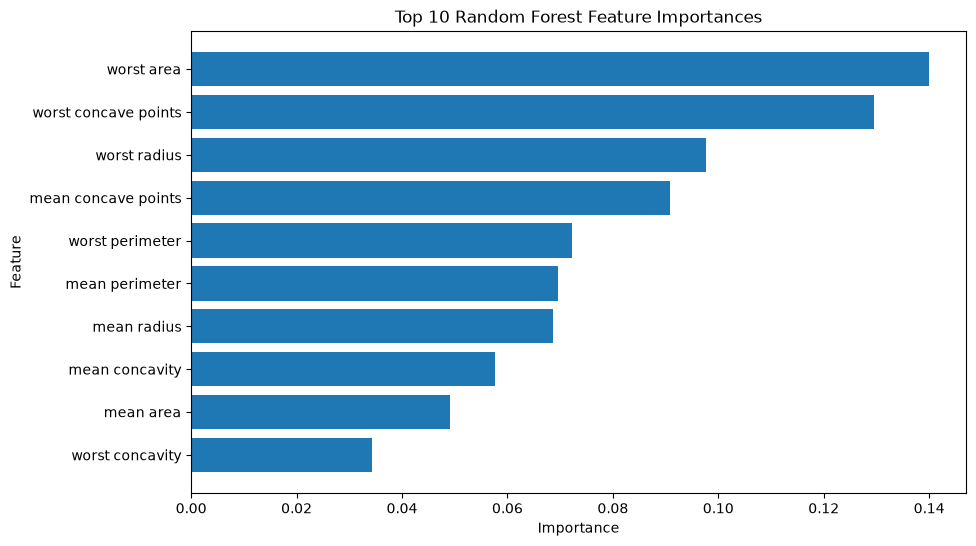

In [23]:
import matplotlib.pyplot as plt

# Select the 10 most important features
top_features = importance_df.head(10)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest Feature Importances")

# Put the most important feature at the top
plt.gca().invert_yaxis()

plt.show()

# Selecting the final model

In [19]:
import pickle 
# import pickle where we can save the model 

In [30]:
with open('random_forest_tree_model.pkl', 'wb') as file:

# store the trained model inside the file. 
    pickle.dump(classifier, file)

print("Random forest model saved successfully")
# Saves the trained random forest to a .pkl file.
#
# 'wb' → write binary mode.
# pickle.dump() → writes the trained model into the file.

Random forest model saved successfully


# Load the model 

In [32]:
import pickle

# Open the saved model file
with open("random_forest_tree_model.pkl", "rb") as file:

    # Load the trained model back into memory
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


# Experiment With Random_forest i do it later. 